# Gene Expression Detective Lab
## Cancer cells before and after Compound X


## Scenario

Human pancreatic ductal adenocarcinoma (PDAC) cells were grown under two conditions:

- **Control:** vehicle only
- **Drug:** 24-hour exposure to an unknown experimental treatment called **Compound X**

Three independent cultures were measured in each condition. Your task is to determine how Compound X changes the cells and to develop a defensible mechanism hypothesis from the expression pattern.

> **Important:** This is a simulated instructional dataset designed to be biologically plausible. It is not a published experiment and should not be represented as real patient data.

## Mini-background

- A gene's expression value is a relative measure of how much messenger RNA was detected.
- **Biological replicates** are independent samples exposed to the same condition.
- **log2 fold change (log2FC)** compares drug-treated cells with controls:
  - `+1` means about **2-fold higher** expression.
  - `+2` means about **4-fold higher** expression.
  - `-1` means about **2-fold lower** expression.
  - `-2` means about **4-fold lower** expression.
- The **FDR** adjusts for testing many genes. In this lab, use `FDR <= 0.05` and `|log2FC| >= 1` as the default criteria for a strong change.
- Expression data can support a mechanism hypothesis, but it cannot by itself prove cell death, protein activity, or the drug's direct molecular target.


## Learning objectives

By the end of the lab, you should be able to:

1. Distinguish controls, treatments, and biological replicates.
2. Calculate and interpret log2 fold change.
3. Apply expression and FDR thresholds to identify changed genes.
4. Infer cellular pathways affected by a drug.
5. Separate a supported conclusion from a claim that requires a follow-up experiment.

## Part 1 - Load the data (about 5 minutes)
Run the cell below. The dataset is embedded, so no upload or internet download is required.

In [ ]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from IPython.display import display

csv_text = r"""Gene,Pathway,Role,Control_1,Control_2,Control_3,Drug_1,Drug_2,Drug_3
ACTB,Housekeeping,Cytoskeletal housekeeping control,169.97,177.19,192.95,172.26,180.14,193.32
GAPDH,Housekeeping,Metabolic housekeeping control,197.78,209.0,222.54,187.29,214.97,227.16
MKI67,Proliferation,Marker of actively cycling cells,89.39,96.61,101.41,21.47,24.4,25.16
PCNA,Proliferation,DNA replication/proliferation marker,114.29,119.91,126.85,41.26,47.51,48.96
CCND1,Cell cycle,Promotes G1-to-S progression,102.74,109.42,117.53,31.38,34.82,36.88
CDK2,Cell cycle,Supports S-phase entry and progression,82.47,84.48,89.41,38.46,43.88,46.94
MYC,Proliferation,Growth-promoting transcription factor,98.53,103.68,109.92,39.74,44.14,46.56
CDKN1A,Cell-cycle arrest,p21; inhibits cyclin-CDK activity,20.47,22.08,23.36,100.11,112.43,117.53
GADD45A,DNA damage/stress,Stress response and cell-cycle arrest,17.09,18.02,19.16,67.08,71.3,77.26
BAX,Apoptosis,Pro-apoptotic mitochondrial regulator,29.87,31.69,33.78,80.02,84.65,92.97
BBC3,Apoptosis,PUMA; pro-apoptotic BH3-only protein,11.0,11.94,12.75,63.18,70.22,74.48
CASP3,Apoptosis,Executioner-caspase transcript,37.4,39.72,42.95,73.32,79.52,84.44
BCL2,Apoptosis,Anti-apoptotic survival factor,64.89,70.52,74.36,23.08,25.03,26.81
HMOX1,Oxidative stress,Stress-inducible heme oxygenase,14.23,14.93,16.01,88.49,98.7,104.46
NQO1,Oxidative stress,Detoxification and oxidative-stress response,25.85,28.2,29.47,96.16,107.61,113.87
ATF4,ER/stress response,Integrated stress-response transcription factor,22.79,23.96,25.28,62.35,66.9,71.19
DDIT3,ER/stress response,CHOP; severe-stress/pro-apoptotic response,9.21,9.85,10.66,47.68,53.43,58.48
VIM,EMT/invasion,Mesenchymal marker vimentin,93.5,101.11,104.52,42.74,46.68,50.04
SNAI1,EMT/invasion,EMT-promoting transcription factor,42.83,43.83,48.01,16.89,18.42,19.17
MMP9,EMT/invasion,Matrix-remodeling/invasion-associated enzyme,56.46,59.52,63.82,18.22,20.84,21.27
CDH1,EMT/invasion,E-cadherin; epithelial adhesion marker,16.66,18.05,19.14,39.08,42.88,44.98
ABCB1,Drug resistance,Drug-efflux transporter,13.45,13.75,14.7,44.02,49.34,51.2
ABCG2,Drug resistance,Drug-efflux transporter,15.18,15.95,16.59,38.06,43.34,46.37
VEGFA,Survival/angiogenesis,Hypoxia/angiogenesis-associated growth factor,62.93,67.84,69.33,33.67,36.46,40.54
"""
data = pd.read_csv(io.StringIO(csv_text))
print(f"Dataset shape: {data.shape[0]} genes x {data.shape[1]} columns")
display(data.head())

Dataset shape: 24 genes x 9 columns


,Gene,Pathway,Role,Control_1,Control_2,Control_3,Drug_1,Drug_2,Drug_3
0,ACTB,Housekeeping,Cytoskeletal housekeeping control,169.97,177.19,192.95,172.26,180.14,193.32
1,GAPDH,Housekeeping,Metabolic housekeeping control,197.78,209.00,222.54,187.29,214.97,227.16
2,MKI67,Proliferation,Marker of actively cycling cells,89.39,96.61,101.41,21.47,24.40,25.16
3,PCNA,Proliferation,DNA replication/proliferation marker,114.29,119.91,126.85,41.26,47.51,48.96
4,CCND1,Cell cycle,Promotes G1-to-S progression,102.74,109.42,117.53,31.38,34.82,36.88


### Question 1
How many genes are present? How many biological replicates are present in each condition? Identify the independent and dependent variables.

**Answer:** The dataset contains 24 genes and three biological replicates for each condition, totaling six independent cell cultures. The independent variable is the treatment condition (vehicle control or Compound X), while the dependent variable is the level of gene expression measured in the cells.




## Part 2 - Define the experimental groups (about 5 minutes)
Inspect the column names, then enter the three control columns and three drug columns. Use quotation marks around each name.

In [ ]:
print(data.columns.tolist())

In [ ]:
# STUDENT EDIT 1: Replace the empty lists with the correct column names.
control_columns = ["Control_1", "Control_2", "Control_3"]
drug_columns = ["Drug_1", "Drug_2", "Drug_3"]

expected = 3
if len(control_columns) != expected or len(drug_columns) != expected:
    raise ValueError(
        "Enter exactly three control columns and three drug columns. "
        "Example format: ['name_1', 'name_2', 'name_3']"
    )

print("Control columns:", control_columns)
print("Drug columns:", drug_columns)

Control columns: ['Control_1', 'Control_2', 'Control_3']
Drug columns: ['Drug_1', 'Drug_2', 'Drug_3']


**Hint if blocked:** The names begin with `Control_` and `Drug_`. Do not include `Gene`, `Pathway`, or `Role`.

## Part 3 - Calculate differential expression (about 10 minutes)
The cell below computes group means, log2FC, a Welch t-test, and FDR. Read the comments before running it.

In [ ]:

# Calculate mean expression and log2 fold change.
results = data[["Gene", "Pathway", "Role"]].copy()
results["Control_mean"] = data[control_columns].mean(axis=1)
results["Drug_mean"] = data[drug_columns].mean(axis=1)
results["log2FC"] = np.log2((results["Drug_mean"] + 1) / (results["Control_mean"] + 1))

# Welch's t-test compares the three control values with the three drug values.
p_values = []
for row_number in data.index:
    test = ttest_ind(
        data.loc[row_number, drug_columns].to_numpy(dtype=float),
        data.loc[row_number, control_columns].to_numpy(dtype=float),
        equal_var=False,
    )
    p_values.append(test.pvalue)
results["p_value"] = p_values

# Benjamini-Hochberg multiple-testing correction.
def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    ranked = p_values[order]
    adjusted = ranked * len(p_values) / np.arange(1, len(p_values) + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)
    output = np.empty_like(adjusted)
    output[order] = adjusted
    return output

results["FDR"] = benjamini_hochberg(results["p_value"])
results["Direction"] = np.where(results["log2FC"] > 0, "Up", "Down")

results.round(3)


,Gene,Pathway,Role,Control_mean,Drug_mean,log2FC,p_value,FDR,Direction
0,ACTB,Housekeeping,Cytoskeletal housekeeping control,180.037,181.907,0.015,0.848,0.885,Up
1,GAPDH,Housekeeping,Metabolic housekeeping control,209.773,209.807,0.000,0.998,0.998,Up
2,MKI67,Proliferation,Marker of actively cycling cells,95.803,23.677,-1.972,0.001,0.003,Down
3,PCNA,Proliferation,DNA replication/proliferation marker,120.350,45.910,-1.371,0.000,0.002,Down
4,CCND1,Cell cycle,Promotes G1-to-S progression,109.897,34.360,-1.649,0.001,0.003,Down
5,CDK2,Cell cycle,Supports S-phase entry and progression,85.453,43.093,-0.971,0.000,0.002,Down
6,MYC,Proliferation,Growth-promoting transcription factor,104.043,43.480,-1.240,0.000,0.002,Down
7,CDKN1A,Cell-cycle arrest,p21; inhibits cyclin-CDK activity,21.970,110.023,2.273,0.003,0.004,Up
8,GADD45A,DNA damage/stress,Stress response and cell-cycle arrest,18.090,71.880,1.933,0.002,0.004,Up
9,BAX,Apoptosis,Pro-apoptotic mitochondrial regulator,31.780,85.880,1.406,0.003,0.004,Up


### Question 2
Examine `ACTB` and `GAPDH`. Are they reasonably stable? Why is that useful when evaluating the experiment?

**Answer:** Yes, ACTB and GAPDH are reasonably stable because their expression levels remain nearly identical between the control and drug-treated groups. ACTB has a log2FC of 0.015, while GAPDH has a log2FC of approximately 0.000. This stability is useful because it suggests that the changes observed in other genes are not simply caused by a general shift in gene expression, making the treatment comparisons more reliable.

## Part 4 - Add absolute fold change and set thresholds (about 8 minutes)
Use the pandas `.abs()` method to calculate the magnitude of each log2FC. Then choose the default thresholds from the mini-background.

In [ ]:
# STUDENT EDIT 2: Replace None with the absolute value of the log2FC column.
# Hint: results["log2FC"].abs()
results["abs_log2FC"] = results["log2FC"].abs()

if results["abs_log2FC"].isna().all():
    raise ValueError("Replace None with results['log2FC'].abs() and rerun this cell.")

results[["Gene", "log2FC", "abs_log2FC"]].head()

,Gene,log2FC,abs_log2FC
0,ACTB,0.014826,0.014826
1,GAPDH,0.000228,0.000228
2,MKI67,-1.971909,1.971909
3,PCNA,-1.371207,1.371207
4,CCND1,-1.649026,1.649026


In [ ]:
# STUDENT EDIT 3: Enter the default cutoffs from the mini-background.
log2fc_cutoff = 1.0
fdr_cutoff = 0.05

if log2fc_cutoff is None or fdr_cutoff is None:
    raise ValueError("Enter numeric values for both cutoffs, then rerun this cell.")

significant = results[
    (results["abs_log2FC"] >= log2fc_cutoff) &
    (results["FDR"] <= fdr_cutoff)
].copy()

significant = significant.sort_values("log2FC", ascending=False)
print(f"Strongly changed genes: {len(significant)}")
display(significant.round(3))

Strongly changed genes: 19


,Gene,Pathway,Role,Control_mean,Drug_mean,log2FC,p_value,FDR,Direction,abs_log2FC
13,HMOX1,Oxidative stress,Stress-inducible heme oxygenase,15.057,97.217,2.613,0.003,0.004,Up,2.613
10,BBC3,Apoptosis,PUMA; pro-apoptotic BH3-only protein,11.897,69.293,2.446,0.003,0.004,Up,2.446
16,DDIT3,ER/stress response,CHOP; severe-stress/pro-apoptotic response,9.907,53.197,2.313,0.005,0.005,Up,2.313
7,CDKN1A,Cell-cycle arrest,p21; inhibits cyclin-CDK activity,21.970,110.023,2.273,0.003,0.004,Up,2.273
8,GADD45A,DNA damage/stress,Stress response and cell-cycle arrest,18.090,71.880,1.933,0.002,0.004,Up,1.933
14,NQO1,Oxidative stress,Detoxification and oxidative-stress response,27.840,105.880,1.890,0.003,0.004,Up,1.890
21,ABCB1,Drug resistance,Drug-efflux transporter,13.967,48.187,1.717,0.003,0.004,Up,1.717
15,ATF4,ER/stress response,Integrated stress-response transcription factor,24.010,66.813,1.439,0.002,0.004,Up,1.439
9,BAX,Apoptosis,Pro-apoptotic mitochondrial regulator,31.780,85.880,1.406,0.003,0.004,Up,1.406
22,ABCG2,Drug resistance,Drug-efflux transporter,15.907,42.590,1.366,0.007,0.008,Up,1.366


### Question 3
How many genes meet both thresholds? List the three most increased and three most decreased genes, including approximate log2FC values.

**Answer:** A total of 19 genes met both thresholds of FDR ≤ 0.05 and absolute log2FC ≥ 1. The three most increased genes were HMOX1 (+2.613), BBC3 (+2.446), and DDIT3 (+2.313). The three most decreased genes were MKI67 (−1.972), CCND1 (−1.649), and MMP9 (approximately −1.53). These results suggest that Compound X increases stress-related and pro-apoptotic gene expression while decreasing genes associated with cell proliferation and invasion.

## Part 5 - Visualize the response (about 8 minutes)
The first plot ranks strongly changed genes. Positive values are higher after drug treatment; negative values are lower.

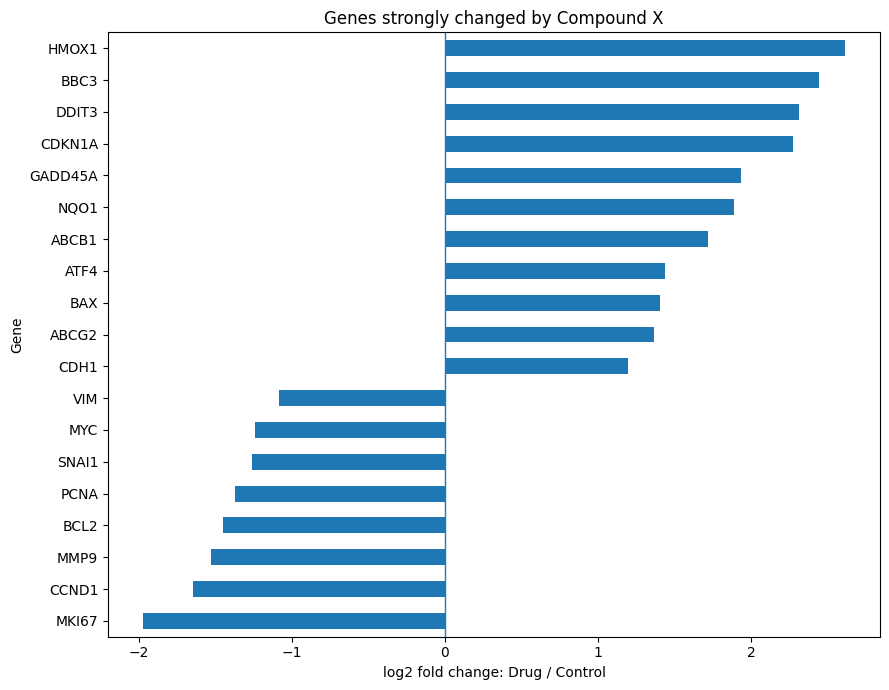

In [ ]:
plot_table = significant.sort_values("log2FC")
ax = plot_table.plot(x="Gene", y="log2FC", kind="barh", legend=False, figsize=(9, 7))
ax.axvline(0, linewidth=1)
ax.set_xlabel("log2 fold change: Drug / Control")
ax.set_ylabel("Gene")
ax.set_title("Genes strongly changed by Compound X")
plt.tight_layout()
plt.show()

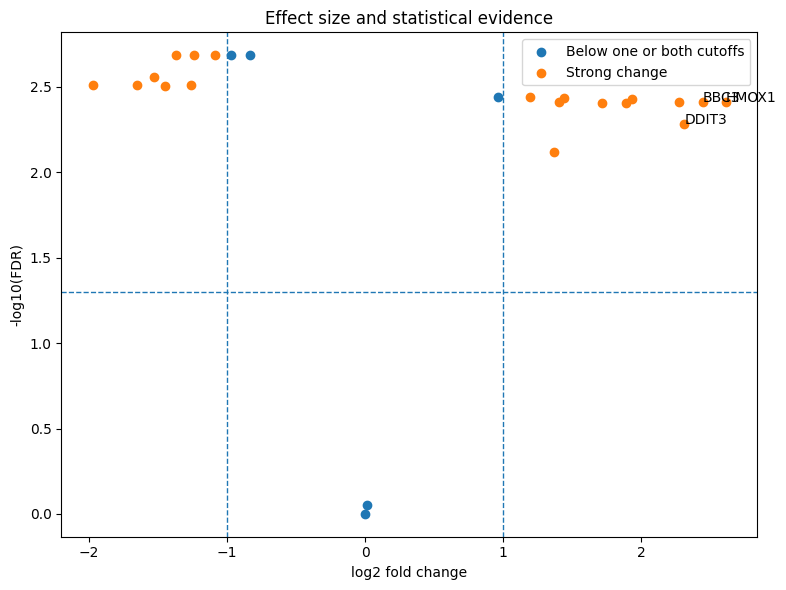

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
other = results.drop(significant.index)
ax.scatter(other["log2FC"], -np.log10(other["FDR"]), label="Below one or both cutoffs")
ax.scatter(significant["log2FC"], -np.log10(significant["FDR"]), label="Strong change")
ax.axvline(log2fc_cutoff, linestyle="--", linewidth=1)
ax.axvline(-log2fc_cutoff, linestyle="--", linewidth=1)
ax.axhline(-np.log10(fdr_cutoff), linestyle="--", linewidth=1)
for _, row in significant.nlargest(3, "abs_log2FC").iterrows():
    ax.annotate(row["Gene"], (row["log2FC"], -np.log10(row["FDR"])))
ax.set_xlabel("log2 fold change")
ax.set_ylabel("-log10(FDR)")
ax.set_title("Effect size and statistical evidence")
ax.legend()
plt.tight_layout()
plt.show()

### Question 4
What does the upper-right region of the second plot represent? What does the upper-left region represent?

**Answer:** The upper-right region represents genes that have increased expression after Compound X treatment and strong statistical evidence. The upper-left region represents genes that have decreased expression after treatment and strong statistical evidence. Genes farther from zero have larger expression changes, while genes higher on the graph have lower FDR values.

## Part 6 - Choose genes and inspect the raw replicates (about 8 minutes)
Choose four genes that help test a coherent hypothesis. Include genes from at least three different pathways.

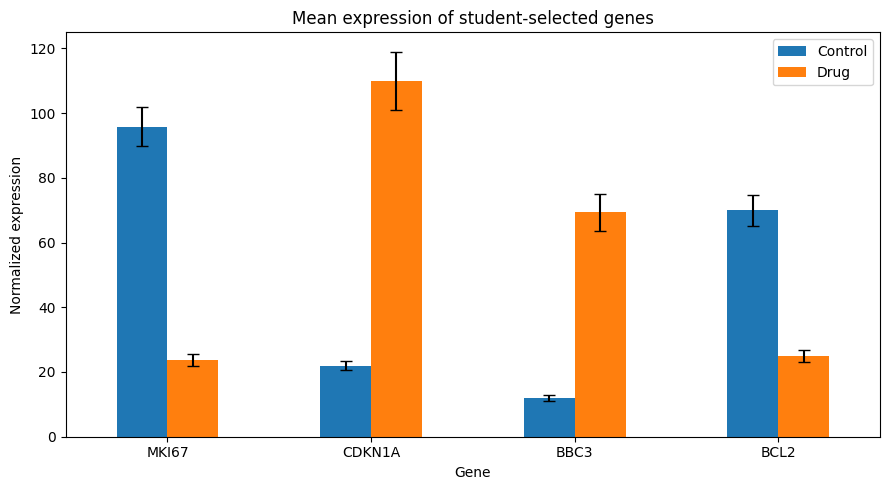

In [ ]:
# STUDENT EDIT 4: Choose four valid gene symbols from the dataset.
genes_to_plot = ["MKI67", "CDKN1A", "BBC3", "BCL2"]

if len(genes_to_plot) != 4:
    raise ValueError("Choose exactly four gene symbols, for example ['GENE1', 'GENE2', 'GENE3', 'GENE4'].")
unknown = sorted(set(genes_to_plot) - set(data["Gene"]))
if unknown:
    raise ValueError(f"These gene names are not in the dataset: {unknown}")

selected = data[data["Gene"].isin(genes_to_plot)].set_index("Gene")
mean_plot = pd.DataFrame({
    "Control": selected[control_columns].mean(axis=1),
    "Drug": selected[drug_columns].mean(axis=1),
})
error_plot = pd.DataFrame({
    "Control": selected[control_columns].std(axis=1),
    "Drug": selected[drug_columns].std(axis=1),
})
ax = mean_plot.plot(kind="bar", yerr=error_plot, capsize=4, figsize=(9, 5))
ax.set_ylabel("Normalized expression")
ax.set_title("Mean expression of student-selected genes")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### Question 5
Why did you choose these four genes? What single claim does the set help you evaluate? Do the replicates appear reasonably consistent?

**Answer:** I chose MKI67, CDKN1A, BBC3, and BCL2 because they represent three pathways: proliferation, cell-cycle arrest, and apoptosis. Together, these genes help evaluate whether Compound X suppresses cancer-cell proliferation while promoting cell-cycle arrest and pro-apoptotic signaling. MKI67 and BCL2 decreased, while CDKN1A and BBC3 increased after treatment. The replicates appear reasonably consistent because the error bars are relatively small compared with the differences between the control and drug-treated groups.

## Part 7 - Summarize pathway evidence (about 5 minutes)
This table counts strongly changed genes and reports the median effect-size magnitude within each pathway. You must still examine the direction and biological role of the individual genes.

In [ ]:
pathway_summary = (
    significant.groupby("Pathway")
    .agg(
        Strongly_changed_genes=("Gene", "count"),
        Median_abs_log2FC=("abs_log2FC", "median"),
    )
    .sort_values(["Strongly_changed_genes", "Median_abs_log2FC"], ascending=False)
)
display(pathway_summary.round(2))

# Gene-level evidence by pathway
display(significant[["Gene", "Pathway", "Role", "log2FC", "FDR"]].sort_values(["Pathway", "log2FC"], ascending=[True, False]).round(3))

,Strongly_changed_genes,Median_abs_log2FC
Pathway,,
EMT/invasion,4,1.23
Apoptosis,3,1.45
Proliferation,3,1.37
Oxidative stress,2,2.25
ER/stress response,2,1.88
Drug resistance,2,1.54
Cell-cycle arrest,1,2.27
DNA damage/stress,1,1.93
Cell cycle,1,1.65


,Gene,Pathway,Role,log2FC,FDR
10,BBC3,Apoptosis,PUMA; pro-apoptotic BH3-only protein,2.446,0.004
9,BAX,Apoptosis,Pro-apoptotic mitochondrial regulator,1.406,0.004
12,BCL2,Apoptosis,Anti-apoptotic survival factor,-1.449,0.003
4,CCND1,Cell cycle,Promotes G1-to-S progression,-1.649,0.003
7,CDKN1A,Cell-cycle arrest,p21; inhibits cyclin-CDK activity,2.273,0.004
8,GADD45A,DNA damage/stress,Stress response and cell-cycle arrest,1.933,0.004
21,ABCB1,Drug resistance,Drug-efflux transporter,1.717,0.004
22,ABCG2,Drug resistance,Drug-efflux transporter,1.366,0.008
20,CDH1,EMT/invasion,E-cadherin; epithelial adhesion marker,1.193,0.004
17,VIM,EMT/invasion,Mesenchymal marker vimentin,-1.085,0.002


### Question 6
Which three cellular responses are most strongly supported? Cite at least two genes for each response and explain whether each gene increased or decreased.

**Answer:** The three cellular responses most strongly supported are reduced cell proliferation, increased pro-apoptotic signaling, and reduced EMT/invasion-associated gene expression. Reduced proliferation is supported by decreased MKI67 and CCND1 expression and increased CDKN1A expression, which promotes cell-cycle arrest. Increased pro-apoptotic signaling is supported by increased BBC3 and BAX expression and decreased BCL2 expression. Reduced EMT/invasion-associated signaling is supported by decreased VIM, SNAI1, and MMP9 expression, along with increased CDH1 expression.

### Question 7
Identify one expression change that could help a surviving cell resist Compound X. Explain the logic.

**Answer:** Increased ABCB1 expression could help surviving cancer cells resist Compound X. ABCB1 encodes a drug-efflux transporter that can pump certain drugs out of cells. If Compound X is transported by ABCB1, increased transporter activity could lower the intracellular drug concentration and potentially reduce the treatment's effectiveness.

### Question 8 - Mechanism hypothesis
Write a 2-3 sentence model of how Compound X affects the cancer cells. Use evidence from at least four genes. Then state one important limitation of your claim.

**Answer:** Compound X appears to suppress pancreatic cancer-cell proliferation and promote cell-cycle arrest, as shown by decreased MKI67 and CCND1 expression and increased CDKN1A expression. Increased BBC3 and BAX expression, along with decreased BCL2 expression, suggests activation of pro-apoptotic signaling, while increased HMOX1 and DDIT3 suggests a cellular stress response. However, gene-expression data alone cannot confirm that apoptosis occurred or identify Compound X's direct molecular target.

### Question 9 - Follow-up experiment
Choose one assay that would test a major part of your model. State the measurement, the control, and the result you would expect if your model is correct. If you used a rescue hint, also state what failed and how you recovered.

**Answer:** I would perform an Annexin V/propidium iodide flow cytometry assay to measure apoptosis in pancreatic cancer cells after 24 hours of Compound X treatment. I would compare the percentage of apoptotic cells in the drug-treated group with vehicle-treated control cells. If my hypothesis is correct, the Compound X-treated cells should show a higher percentage of apoptotic cells than the control group. I did not use the rescue hint.

## Optional extension
Change `log2fc_cutoff` from 1.0 to 0.5, rerun the threshold and plotting cells, and identify one additional gene that enters the list. Does it strengthen or complicate your model?


## Troubleshooting and rescue route

Try these steps in order:

1. Read the red error message; it usually identifies the exact variable or column that needs editing.
2. Make sure gene and column names are inside quotation marks and separated by commas.
3. Run the current cell again with **Shift + Enter**.
4. If later cells fail, rerun every earlier cell from the top.
5. If Colab disconnects, choose **Runtime > Reconnect**, then **Runtime > Run all above**.
6. If you are still blocked after a genuine attempt, open the final **Rescue Cell**, copy the needed value, and state in Question 9 what failed and how you recovered.


In [ ]:
# RESCUE CELL - use only after a genuine attempt.
# Copy the needed values into the earlier STUDENT EDIT cells, then rerun from that point.

rescue_control_columns = ["Control_1", "Control_2", "Control_3"]
rescue_drug_columns = ["Drug_1", "Drug_2", "Drug_3"]
rescue_abs_log2FC_code = 'results["log2FC"].abs()'
rescue_log2fc_cutoff = 1.0
rescue_fdr_cutoff = 0.05
rescue_example_genes = ["MKI67", "CDKN1A", "BBC3", "ABCB1"]

print("Control:", rescue_control_columns)
print("Drug:", rescue_drug_columns)
print("Absolute-value expression:", rescue_abs_log2FC_code)
print("Cutoffs:", rescue_log2fc_cutoff, rescue_fdr_cutoff)
print("Example genes:", rescue_example_genes)

Control: ['Control_1', 'Control_2', 'Control_3']
Drug: ['Drug_1', 'Drug_2', 'Drug_3']
Absolute-value expression: results["log2FC"].abs()
Cutoffs: 1.0 0.05
Example genes: ['MKI67', 'CDKN1A', 'BBC3', 'ABCB1']


## Submission checklist

- Every required code cell runs without an unresolved error.
- All nine questions have substantive answers.
- Plots and tables are visible in the notebook.
- Save the notebook with your last name in the filename.
- Submit the completed `.ipynb` file to the designated Canvas dropbox before leaving lab, unless your instructor announces a different deadline.